# Multi-Objective Regularized Evolution — Full Grid

Runs MO-RE on every combination of **dataset × hardware platform**,  
then compares each resulting Pareto front against the exhaustive (true) front.

**Datasets** : cifar10, cifar100, ImageNet16-120  
**Platforms** : edgegpu, raspi4, edgetpu, pixel3, eyeriss, fpga  
→ 18 combinations total

For each combination the notebook produces:
- The MO-RE Pareto front (CSV)
- A comparison plot (true front vs MO-RE front)
- Three metrics: Hypervolume ratio, GD, IGD

A global summary table is saved at the end.

## 0 · Configuration

In [1]:
import numpy as np

# ── Paths ─────────────────────────────────────────────────────────────────────
HW_NAS_ROOT   = "/kaggle/input/datasets/djouaheryasmine/hw-nas-bench-main/HW-NAS-Bench-main"
HW_NAS_PICKLE = f"{HW_NAS_ROOT}/HW-NAS-Bench-v1_0.pickle"
NAS201_ROOT   = "/kaggle/input/datasets/djouaheryasmine/nas-bench-201/NAS-Bench-201"
ACC_CSV       = "/kaggle/input/datasets/djouaheryasmine/nasbench201-accuracies/nasbench201_accuracies.csv"

# Exhaustive results produced by your baseline notebook
EXHAUSTIVE_ROOT = "/kaggle/input/datasets/djouaheryasmine/results/Results"

# Output folder for MO-RE results
OUTPUT_ROOT = "/kaggle/working/mo_re_results"

# ── Search grid ───────────────────────────────────────────────────────────────
DATASETS   = ["cifar10", "cifar100", "ImageNet16-120"]
PLATFORMS  = ["edgegpu", "raspi4", "pixel3", "fpga"]

# ── Evolution hyper-parameters ────────────────────────────────────────────────
POPULATION_SIZE = 50
TOURNAMENT_SIZE = 10
NUM_CYCLES      = 200
NUM_RUNS        = 5
SEED            = 42

SEARCH_SPACE_SIZE = 15_625

np.random.seed(SEED)
print("Grid: ", len(DATASETS), "datasets ×", len(PLATFORMS), "platforms =", len(DATASETS)*len(PLATFORMS), "combinations")
print(f"Evolution: P={POPULATION_SIZE}, S={TOURNAMENT_SIZE}, C={NUM_CYCLES}, {NUM_RUNS} runs each")

Grid:  3 datasets × 4 platforms = 12 combinations
Evolution: P=50, S=10, C=200, 5 runs each


## 1 · Imports & benchmark loading

In [2]:
import sys, os, collections
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

sys.path.insert(0, HW_NAS_ROOT)
sys.path.insert(0, NAS201_ROOT)

from hw_nas_bench_api import HWNASBenchAPI as HWAPI

hw_api = HWAPI(HW_NAS_PICKLE, search_space="nasbench201")
acc_df = pd.read_csv(ACC_CSV).set_index("arch_index")

os.makedirs(OUTPUT_ROOT, exist_ok=True)

print("Benchmarks loaded.")

Benchmarks loaded.


## 2 · Core functions

Oracle, mutation, Pareto utilities, and metrics — all in one place.

In [3]:
# ── Oracle ────────────────────────────────────────────────────────────────────

def evaluate(arch_index: int, dataset: str, latency_key: str) -> dict:
    """Return accuracy and latency for one architecture."""
    acc_col = f"acc_{dataset}"
    return {
        "arch_index" : arch_index,
        "accuracy"   : float(acc_df.loc[arch_index, acc_col]),
        "latency"    : float(hw_api.query_by_index(arch_index, dataset)[latency_key]),
    }


# ── Mutation ──────────────────────────────────────────────────────────────────

def mutate(arch_index: int, rng: np.random.Generator) -> int:
    """Sample a different architecture index at random."""
    child = arch_index
    while child == arch_index:
        child = int(rng.integers(0, SEARCH_SPACE_SIZE))
    return child


# ── Pareto utilities ──────────────────────────────────────────────────────────

def dominates(a: dict, b: dict) -> bool:
    """True if a dominates b (maximize accuracy, minimize latency)."""
    return (
        a["accuracy"] >= b["accuracy"] and
        a["latency"]  <= b["latency"]  and
        (a["accuracy"] > b["accuracy"] or a["latency"] < b["latency"])
    )


def select_pareto_best(sample: list) -> dict:
    """
    Tournament parent selection: return the non-dominated model
    in the sample. Tiebreak by highest accuracy.
    Replaces: parent = max(sample, key=lambda m: m['accuracy'])
    """
    non_dominated = [
        c for c in sample
        if not any(dominates(o, c) for o in sample if o is not c)
    ]
    return max(non_dominated, key=lambda m: m["accuracy"])


def compute_pareto_front(models: list) -> list:
    """Return the non-dominated subset of a list of evaluated models."""
    return [
        m for m in models
        if not any(dominates(o, m) for o in models if o is not m)
    ]


def to_array(front: list) -> np.ndarray:
    """Convert list of dicts to (N, 2) array: [accuracy, latency]."""
    return np.array([[m["accuracy"], m["latency"]] for m in front])


# ── Comparison metrics ────────────────────────────────────────────────────────

def hypervolume_2d(front_arr: np.ndarray, ref_point: tuple) -> float:
    """
    2D hypervolume in the space (maximize accuracy, minimize latency).
    Converted to minimization as (-accuracy, latency).
    ref_point = (min_accuracy - margin, max_latency + margin).
    """
    pts = np.column_stack([-front_arr[:, 0], front_arr[:, 1]])
    ref = np.array([-ref_point[0], ref_point[1]])
    pts = pts[np.argsort(pts[:, 0])]   # sort by -accuracy ascending
    hv, prev_y = 0.0, ref[1]
    for pt in pts:
        if pt[1] < prev_y:
            hv += (ref[0] - pt[0]) * (prev_y - pt[1])
            prev_y = pt[1]
    return hv


def normalize(arr: np.ndarray, vmin: np.ndarray, vmax: np.ndarray) -> np.ndarray:
    return (arr - vmin) / (vmax - vmin + 1e-8)


def gd(approx: np.ndarray, true: np.ndarray) -> float:
    """Generational Distance — proximity of approx to true front."""
    return np.mean([np.min(np.linalg.norm(true - pt, axis=1)) for pt in approx])


def igd(approx: np.ndarray, true: np.ndarray) -> float:
    """Inverted GD — coverage of the true front by approx."""
    return np.mean([np.min(np.linalg.norm(approx - pt, axis=1)) for pt in true])


def compute_metrics(approx_front: list, true_front: list) -> dict:
    """Compute HV ratio, GD, IGD between approximated and true Pareto fronts."""
    approx_arr = to_array(approx_front)
    true_arr   = to_array(true_front)

    all_acc = np.concatenate([approx_arr[:, 0], true_arr[:, 0]])
    all_lat = np.concatenate([approx_arr[:, 1], true_arr[:, 1]])
    ref     = (np.min(all_acc) - 1.0, np.max(all_lat) + 1.0)

    hv_true   = hypervolume_2d(true_arr,   ref)
    hv_approx = hypervolume_2d(approx_arr, ref)
    hv_ratio  = hv_approx / hv_true * 100 if hv_true > 0 else 0.0

    vmin = np.array([np.min(all_acc), np.min(all_lat)])
    vmax = np.array([np.max(all_acc), np.max(all_lat)])
    approx_n = normalize(approx_arr, vmin, vmax)
    true_n   = normalize(true_arr,   vmin, vmax)

    return {
        "hv_true"   : hv_true,
        "hv_approx" : hv_approx,
        "hv_ratio"  : hv_ratio,
        "gd"        : gd(approx_n, true_n),
        "igd"       : igd(approx_n, true_n),
        "front_size_true"   : len(true_front),
        "front_size_approx" : len(approx_front),
    }


print("All functions defined.")

All functions defined.


## 3 · MO-RE algorithm

In [4]:
def mo_regularized_evolution(dataset: str, latency_key: str, seed: int) -> list:
    """
    Multi-Objective Regularized Evolution (Algorithm 1, Real et al. 2019).
    One change: parent selection uses Pareto dominance instead of max accuracy.
    Returns full history (list of evaluated model dicts).
    """
    rng        = np.random.default_rng(seed)
    population = collections.deque()  # FIFO queue — left = oldest
    history    = []

    # Phase 1: random initialisation
    while len(population) < POPULATION_SIZE:
        arch  = int(rng.integers(0, SEARCH_SPACE_SIZE))
        model = evaluate(arch, dataset, latency_key)
        population.append(model)
        history.append(model)

    # Phase 2: evolution cycles
    for _ in range(NUM_CYCLES):
        pop_list = list(population)
        indices  = rng.integers(0, len(population), size=TOURNAMENT_SIZE)
        sample   = [pop_list[i] for i in indices]

        parent     = select_pareto_best(sample)          # ← multi-objective change
        child_arch = mutate(parent["arch_index"], rng)
        child      = evaluate(child_arch, dataset, latency_key)

        population.append(child)
        history.append(child)
        population.popleft()                             # ← aging: kill oldest

    return history

## 4 · Plot helper

In [5]:
def plot_comparison(true_front, approx_front, all_history, metrics,
                    dataset, platform, save_path):
    """
    Two-panel figure:
      Left  — scatter of all MO-RE evaluated models + both Pareto fronts
      Right — metrics bar chart (HV ratio, GD, IGD)
    """
    true_arr   = to_array(true_front)
    approx_arr = to_array(approx_front)

    true_s   = true_arr[np.argsort(true_arr[:, 1])]
    approx_s = approx_arr[np.argsort(approx_arr[:, 1])]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle(f"{dataset} / {platform}", fontsize=13, fontweight="bold")

    # Left: Pareto fronts
    ax1.scatter(
        [m["latency"]  for m in all_history],
        [m["accuracy"] for m in all_history],
        s=8, alpha=0.2, color="steelblue", label="MO-RE evaluated"
    )
    ax1.plot(true_s[:, 1],   true_s[:, 0],
             "o-",  color="black", lw=2, ms=5,
             label=f"True front ({len(true_front)} pts)")
    ax1.plot(approx_s[:, 1], approx_s[:, 0],
             "s--", color="red",   lw=2, ms=5,
             label=f"MO-RE front ({len(approx_front)} pts)")
    ax1.set_xlabel("Latency (ms)")
    ax1.set_ylabel("Accuracy (%)")
    ax1.set_title("Pareto fronts")
    ax1.legend(fontsize=8)

    # Right: metrics
    metric_names  = ["HV ratio (%)", "GD (×100)", "IGD (×100)"]
    metric_values = [
        metrics["hv_ratio"],
        metrics["gd"]  * 100,
        metrics["igd"] * 100,
    ]
    colors = ["#2ecc71", "#e74c3c", "#e67e22"]
    bars = ax2.bar(metric_names, metric_values, color=colors, width=0.5)
    for bar, val in zip(bars, metric_values):
        ax2.text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.3,
                 f"{val:.2f}", ha="center", va="bottom", fontsize=10)
    ax2.set_ylim(0, max(metric_values) * 1.25)
    ax2.set_title("Quality metrics")
    ax2.axhline(100, color="black", lw=1, ls=":", label="HV perfect = 100%")
    ax2.axhline(0,   color="gray",  lw=1, ls=":")
    ax2.legend(fontsize=8)

    plt.tight_layout()
    plt.savefig(save_path, dpi=130, bbox_inches="tight")
    plt.close()

print("Plot helper defined.")

Plot helper defined.


## 5 · Main loop — all dataset × platform combinations

In [6]:
summary_rows = []
total = len(DATASETS) * len(PLATFORMS)
done  = 0

for dataset in DATASETS:
    for platform in PLATFORMS:
        done += 1
        latency_key = f"{platform}_latency"
        combo_label = f"{dataset}/{platform}"

        print(f"[{done:>2}/{total}]  {combo_label}")

        # ── 1. Load true (exhaustive) Pareto front ────────────────────────────
        true_csv = os.path.join(
            EXHAUSTIVE_ROOT, dataset, platform, "pareto_front.csv"
        )
        if not os.path.exists(true_csv):
            print(f"       WARNING: exhaustive front not found at {true_csv}, skipping.")
            continue

        true_df    = pd.read_csv(true_csv)
        true_front = true_df[["accuracy", "latency"]].to_dict("records")

        # ── 2. Run MO-RE (NUM_RUNS independent runs) ──────────────────────────
        all_histories = []
        for run in range(NUM_RUNS):
            history = mo_regularized_evolution(dataset, latency_key, seed=SEED + run)
            all_histories.append(history)

        # Aggregate: merge all histories, extract global Pareto front
        all_models   = [m for h in all_histories for m in h]
        approx_front = compute_pareto_front(all_models)

        # ── 3. Compute metrics ────────────────────────────────────────────────
        metrics = compute_metrics(approx_front, true_front)
        print(f"       HV ratio: {metrics['hv_ratio']:.1f}%  "
              f"GD: {metrics['gd']:.4f}  "
              f"IGD: {metrics['igd']:.4f}  "
              f"front sizes: true={metrics['front_size_true']}  "
              f"MO-RE={metrics['front_size_approx']}")

        # ── 4. Save MO-RE Pareto front CSV ────────────────────────────────────
        out_dir = os.path.join(OUTPUT_ROOT, dataset, platform)
        os.makedirs(out_dir, exist_ok=True)

        approx_df = pd.DataFrame(approx_front)
        approx_df.to_csv(os.path.join(out_dir, "mo_re_front.csv"), index=False)

        # ── 5. Save comparison plot ───────────────────────────────────────────
        plot_path = os.path.join(out_dir, "comparison.png")
        plot_comparison(
            true_front, approx_front, all_models,
            metrics, dataset, platform, plot_path
        )

        # ── 6. Accumulate summary row ─────────────────────────────────────────
        summary_rows.append({
            "dataset"            : dataset,
            "platform"           : platform,
            "evaluations"        : len(all_models),
            "front_size_true"    : metrics["front_size_true"],
            "front_size_mo_re"   : metrics["front_size_approx"],
            "hv_ratio_%"         : round(metrics["hv_ratio"],  2),
            "gd"                 : round(metrics["gd"],         4),
            "igd"                : round(metrics["igd"],        4),
        })

print("\nAll combinations done.")

[ 1/12]  cifar10/edgegpu
       HV ratio: 99.5%  GD: 0.0058  IGD: 0.0091  front sizes: true=23  MO-RE=13
[ 2/12]  cifar10/raspi4
       HV ratio: 99.5%  GD: 0.0087  IGD: 0.0128  front sizes: true=43  MO-RE=31
[ 3/12]  cifar10/pixel3
       HV ratio: 99.1%  GD: 0.0165  IGD: 0.0183  front sizes: true=37  MO-RE=26
[ 4/12]  cifar10/fpga
       HV ratio: 95.4%  GD: 0.0505  IGD: 0.0556  front sizes: true=21  MO-RE=13
[ 5/12]  cifar100/edgegpu
       HV ratio: 98.8%  GD: 0.0120  IGD: 0.0149  front sizes: true=25  MO-RE=20
[ 6/12]  cifar100/raspi4
       HV ratio: 98.9%  GD: 0.0230  IGD: 0.0125  front sizes: true=34  MO-RE=27
[ 7/12]  cifar100/pixel3
       HV ratio: 97.8%  GD: 0.0137  IGD: 0.0211  front sizes: true=33  MO-RE=21
[ 8/12]  cifar100/fpga
       HV ratio: 94.9%  GD: 0.0479  IGD: 0.0450  front sizes: true=11  MO-RE=14
[ 9/12]  ImageNet16-120/edgegpu
       HV ratio: 98.3%  GD: 0.0127  IGD: 0.0258  front sizes: true=39  MO-RE=16
[10/12]  ImageNet16-120/raspi4
       HV ratio: 98.0% 

## 6 · Global summary table

In [7]:
summary_df = pd.DataFrame(summary_rows)

# Save
summary_path = os.path.join(OUTPUT_ROOT, "summary.csv")
summary_df.to_csv(summary_path, index=False)

# Display
print(summary_df.to_string(index=False))
print(f"\nSaved to: {summary_path}")

       dataset platform  evaluations  front_size_true  front_size_mo_re  hv_ratio_%     gd    igd
       cifar10  edgegpu         1250               23                13       99.53 0.0058 0.0091
       cifar10   raspi4         1250               43                31       99.54 0.0087 0.0128
       cifar10   pixel3         1250               37                26       99.14 0.0165 0.0183
       cifar10     fpga         1250               21                13       95.36 0.0505 0.0556
      cifar100  edgegpu         1250               25                20       98.85 0.0120 0.0149
      cifar100   raspi4         1250               34                27       98.88 0.0230 0.0125
      cifar100   pixel3         1250               33                21       97.81 0.0137 0.0211
      cifar100     fpga         1250               11                14       94.91 0.0479 0.0450
ImageNet16-120  edgegpu         1250               39                16       98.31 0.0127 0.0258
ImageNet16-120   ras

## 7 · Summary heatmaps

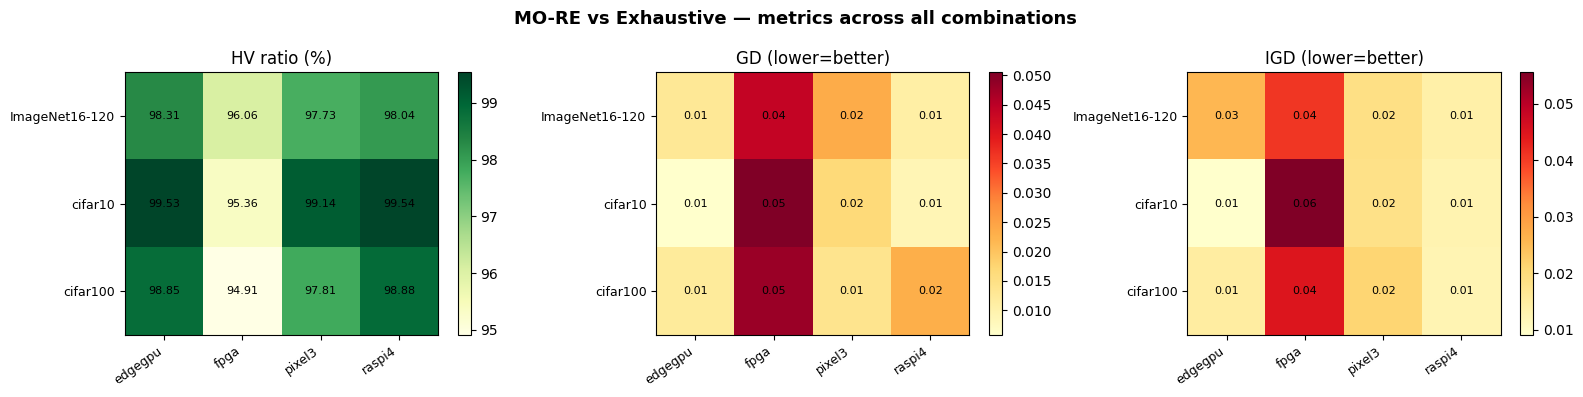

Saved: /kaggle/working/mo_re_results/summary_heatmaps.png


In [8]:
metrics_to_plot = {
    "hv_ratio_%" : {"label": "HV ratio (%)",   "cmap": "YlGn",  "better": "high"},
    "gd"         : {"label": "GD (lower=better)", "cmap": "YlOrRd","better": "low"},
    "igd"        : {"label": "IGD (lower=better)","cmap": "YlOrRd","better": "low"},
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle("MO-RE vs Exhaustive — metrics across all combinations",
             fontsize=13, fontweight="bold")

for ax, (col, cfg) in zip(axes, metrics_to_plot.items()):
    pivot = summary_df.pivot(index="dataset", columns="platform", values=col)
    im = ax.imshow(pivot.values, cmap=cfg["cmap"], aspect="auto")
    plt.colorbar(im, ax=ax)

    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=35, ha="right", fontsize=9)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index, fontsize=9)
    ax.set_title(cfg["label"])

    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = pivot.values[i, j]
            if not np.isnan(val):
                ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                        fontsize=8, color="black")

plt.tight_layout()
heatmap_path = os.path.join(OUTPUT_ROOT, "summary_heatmaps.png")
plt.savefig(heatmap_path, dpi=130, bbox_inches="tight")
plt.show()
print(f"Saved: {heatmap_path}")

## 8 · Output file listing

In [9]:
print("Output files")
print("=" * 55)
for root, dirs, files in os.walk(OUTPUT_ROOT):
    level  = root.replace(OUTPUT_ROOT, "").count(os.sep)
    indent = "  " * level
    rel    = os.path.relpath(root, OUTPUT_ROOT)
    if rel != ".":
        print(f"{indent}{rel}/")
    for fname in sorted(files):
        fpath = os.path.join(root, fname)
        size  = os.path.getsize(fpath)
        print(f"{'  ' * (level+1)}{fname}  ({size/1024:.1f} KB)")

Output files
  summary.csv  (0.6 KB)
  summary_heatmaps.png  (85.2 KB)
  cifar100/
    cifar100/pixel3/
      comparison.png  (116.8 KB)
      mo_re_front.csv  (0.7 KB)
    cifar100/fpga/
      comparison.png  (104.5 KB)
      mo_re_front.csv  (0.5 KB)
    cifar100/edgegpu/
      comparison.png  (119.5 KB)
      mo_re_front.csv  (0.8 KB)
    cifar100/raspi4/
      comparison.png  (115.6 KB)
      mo_re_front.csv  (1.1 KB)
  ImageNet16-120/
    ImageNet16-120/pixel3/
      comparison.png  (124.9 KB)
      mo_re_front.csv  (1.2 KB)
    ImageNet16-120/fpga/
      comparison.png  (114.0 KB)
      mo_re_front.csv  (0.5 KB)
    ImageNet16-120/edgegpu/
      comparison.png  (127.8 KB)
      mo_re_front.csv  (0.7 KB)
    ImageNet16-120/raspi4/
      comparison.png  (123.9 KB)
      mo_re_front.csv  (1.1 KB)
  cifar10/
    cifar10/pixel3/
      comparison.png  (104.8 KB)
      mo_re_front.csv  (0.6 KB)
    cifar10/fpga/
      comparison.png  (94.3 KB)
      mo_re_front.csv  (0.3 KB)
    cifar10

---
## What changed vs. single-objective RE

| Component | Original RE (Real et al. 2019) | This notebook |
|---|---|---|
| Fitness | Single: accuracy | Two: accuracy + latency |
| Parent selection | `max(sample, key=accuracy)` | `select_pareto_best(sample)` |
| Aging (kill oldest) | ✓ | ✓ unchanged |
| Output | Single best model | Pareto front per combination |
| Comparison | — | HV ratio, GD, IGD vs. exhaustive true front |

In [10]:
import shutil

# Zip the entire results folder into a single file
shutil.make_archive(
    base_name="/kaggle/working/mo_re_results",   # output zip path (no .zip extension)
    format="zip",
    root_dir="/kaggle/working",
    base_dir="mo_re_results"                     # folder to zip
)

print("Done. Download mo_re_results.zip from the Output tab.")

Done. Download mo_re_results.zip from the Output tab.
